# LSTM Indirect Wind Power Forecast — Fixed

This is a corrected notebook copy. The original notebook is not modified.
The cell order intentionally follows the original workflow: load data,
preprocess, build hourly sequences, split, train, evaluate, plot, and save.


## 1. Imports and reproducibility


In [1]:
from pathlib import Path
import random
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    warnings.warn("Deterministic TensorFlow operations are unavailable in this runtime.")

def find_project_root():
    """Find the repository root when Jupyter is launched from inside the repository."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "Data Download").is_dir() and (candidate / "FCNN Direct Method").is_dir():
            return candidate
    raise FileNotFoundError(
        "Cannot locate the repository root containing 'Data Download' and the method folders."
    )


PROJECT_ROOT = find_project_root()
RAW_DATA_DIR = PROJECT_ROOT / "Data Download"
FIXED_DATA_DIR = PROJECT_ROOT / "fixed_data"
DATA_FILE = FIXED_DATA_DIR / "ercot_2021_2024_hourly.csv"
OUTPUT_DIR = PROJECT_ROOT / "fixed_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TIME_COLUMN = "time"


## 2. Timestamp-safe data helpers and metrics


In [2]:
def dense_one_hot():
    """Support both current and older scikit-learn OneHotEncoder APIs."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def detect_time_column(frame, value_columns):
    preferred = [
        "Time (Hour-Ending)", "time", "Time", "timestamp", "Timestamp",
        "datetime", "Datetime", "date", "Date",
    ]
    for column in preferred:
        if column in frame.columns:
            return column
    values = set(value_columns)
    candidates = [
        column for column in frame.columns
        if column not in values
        and ("time" in str(column).lower() or "date" in str(column).lower())
    ]
    if len(candidates) == 1:
        return candidates[0]
    other_columns = [column for column in frame.columns if column not in values]
    return other_columns[0] if len(other_columns) == 1 else None


def read_source(filename, column_mapping, reference_time=None):
    """Read selected values and preserve/validate their timestamps."""
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Required input file not found: {path.resolve()}")
    raw = pd.read_excel(path)
    missing = [column for column in column_mapping if column not in raw.columns]
    if missing:
        raise KeyError(f"{filename} is missing columns: {missing}")

    time_column = detect_time_column(raw, column_mapping.keys())
    if time_column is None:
        if reference_time is None or len(raw) != len(reference_time):
            raise ValueError(
                f"{filename} has no usable timestamp and cannot be safely aligned."
            )
        warnings.warn(
            f"{filename} has no detectable timestamp; attaching the validated "
            "canonical timeline. Add timestamps to remove this fallback."
        )
        time_values = reference_time.reset_index(drop=True)
    else:
        time_values = raw[time_column]

    result = pd.DataFrame({TIME_COLUMN: pd.to_datetime(time_values, errors="coerce")})
    for source_column, output_column in column_mapping.items():
        result[output_column] = pd.to_numeric(raw[source_column], errors="coerce")
    invalid = result.isna().any(axis=1)
    if invalid.any():
        warnings.warn(f"Dropping {int(invalid.sum())} invalid rows from {filename}.")
        result = result.loc[~invalid].copy()
    result = result.sort_values(TIME_COLUMN).reset_index(drop=True)
    if result[TIME_COLUMN].duplicated().any():
        raise ValueError(
            f"{filename} contains duplicate timestamps. Resolve timezone/DST "
            "ambiguity instead of dropping duplicates."
        )
    return result


def merge_sources(base, labelled_sources):
    """Perform explicit one-to-one timestamp joins and report any row loss."""
    merged = base.copy()
    for label, source in labelled_sources:
        before = len(merged)
        merged = merged.merge(source, on=TIME_COLUMN, how="inner", validate="one_to_one")
        if len(merged) != before or len(merged) != len(source):
            print(
                f"Timestamp intersection with {label}: master {before}, "
                f"source {len(source)}, retained {len(merged)}"
            )
    if merged.empty:
        raise ValueError("No common timestamps remain after input alignment.")
    return merged.sort_values(TIME_COLUMN).reset_index(drop=True)


def make_sequences(feature_values, target_values, timestamps, history_hours=24):
    """Create only windows whose every adjacent timestamp is exactly one hour apart."""
    X, y, target_times, target_positions = [], [], [], []
    one_hour = pd.Timedelta(hours=1)
    for target_position in range(history_hours, len(timestamps)):
        start = target_position - history_hours
        window_times = timestamps.iloc[start:target_position + 1]
        if not window_times.diff().iloc[1:].eq(one_hour).all():
            continue
        X.append(feature_values[start:target_position].copy())
        y.append(target_values[target_position])
        target_times.append(timestamps.iloc[target_position])
        target_positions.append(target_position)
    if not X:
        raise ValueError("No continuous hourly forecasting windows were found.")
    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32).reshape(-1, 1),
        pd.DatetimeIndex(target_times),
        np.asarray(target_positions, dtype=np.int64),
    )


def regression_metrics(actual, predicted, mape_min_actual=1.0):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    if actual.shape != predicted.shape or actual.size == 0:
        raise ValueError("Actual and predicted arrays must have the same non-zero length.")
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Metrics require finite values.")
    error = predicted - actual
    mse = mean_squared_error(actual, predicted)
    variance = np.var(actual)
    smape_denominator = np.abs(actual) + np.abs(predicted)
    smape_terms = np.divide(
        2.0 * np.abs(error), smape_denominator,
        out=np.zeros_like(smape_denominator), where=smape_denominator > 1e-9,
    )
    mape_mask = np.abs(actual) > mape_min_actual
    return {
        "sample_count": int(actual.size),
        "mean_error_mw": float(np.mean(error)),
        "mae_mw": float(mean_absolute_error(actual, predicted)),
        "rmse_mw": float(np.sqrt(mse)),
        "mse_mw2": float(mse),
        "nmse": float(mse / variance) if variance > 1e-12 else np.nan,
        "r2": float(r2_score(actual, predicted)),
        "smape_percent": float(np.mean(smape_terms) * 100.0),
        "masked_mape_percent": (
            float(np.mean(np.abs(error[mape_mask] / actual[mape_mask])) * 100.0)
            if mape_mask.any() else np.nan
        ),
        "mape_min_actual_mw": float(mape_min_actual),
        "mape_sample_count": int(mape_mask.sum()),
    }


## 3. Load and align source data by timestamp


In [3]:
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Prepared data not found: {DATA_FILE}\n"
        "Run Data Preparation/01_Prepare_Available_ERCOT_Data.ipynb first."
    )

load_data = pd.read_csv(DATA_FILE, parse_dates=[TIME_COLUMN])
required_columns = {
    TIME_COLUMN, "total_load", "solar_generation", "solar_installed",
    "wind_generation", "wind_installed", "net_load", "clear_sky_proxy",
}
missing_columns = required_columns.difference(load_data.columns)
if missing_columns:
    raise KeyError(f"Prepared data is missing columns: {sorted(missing_columns)}")
if load_data[TIME_COLUMN].duplicated().any():
    raise ValueError("Prepared data contains duplicate timestamps.")
load_data = load_data.sort_values(TIME_COLUMN).reset_index(drop=True)
print("Prepared data:", DATA_FILE)
print("Shape:", load_data.shape)
print("Range:", load_data[TIME_COLUMN].min(), "to", load_data[TIME_COLUMN].max())
load_data.head()


Prepared data: c:\Users\lfang7\Project\Report\Conference paper\2026 SmartGridComm\Final Code\Fixed Methods\fixed_data\ercot_2021_2024_hourly.csv
Shape: (35065, 8)
Range: 2021-01-01 06:00:00 to 2025-01-01 06:00:00


,time,wind_generation,wind_installed,total_load,solar_generation,solar_installed,net_load,clear_sky_proxy
0,2021-01-01 06:00:00,13924.505859,31073,44084.976562,0.00907,5649,30160.461633,0.0
1,2021-01-01 07:00:00,14046.383789,31073,43445.851562,0.00907,5649,29399.458704,0.0
2,2021-01-01 08:00:00,14473.155273,31073,43129.835938,0.00907,5649,28656.671594,0.0
3,2021-01-01 09:00:00,14060.383789,31073,42988.664062,0.00907,5649,28928.271204,0.0
4,2021-01-01 10:00:00,12590.800781,31073,43189.539062,0.00907,5649,30598.729211,0.0


## 4. Chronological boundaries and training-only preprocessing


In [4]:
HISTORY_HOURS = 24
TARGET_COLUMN = "wind_generation"
ARTIFACT_NAME = "lstm_indirect_wind_generation"

load_data = load_data.sort_values(TIME_COLUMN).reset_index(drop=True)
local_time = load_data[TIME_COLUMN].dt.tz_localize("UTC").dt.tz_convert("America/Chicago")
load_data["hour"] = local_time.dt.hour
load_data["day"] = local_time.dt.day
load_data["month"] = local_time.dt.month
load_data["year"] = local_time.dt.year

validation_index = int(len(load_data) * 0.90)
test_index = int(len(load_data) * 0.95)
validation_start = load_data.loc[validation_index, TIME_COLUMN]
test_start = load_data.loc[test_index, TIME_COLUMN]
training_rows = load_data[TIME_COLUMN] < validation_start

numeric_feature_columns = ['wind_generation', 'wind_installed']
transformations = [
    ("hour_enc", dense_one_hot(), ["hour"]),
    ("day_enc", dense_one_hot(), ["day"]),
    ("month_enc", dense_one_hot(), ["month"]),
    ("year_enc", dense_one_hot(), ["year"]),
]
transformations.extend(
    (f"{column}_scale", StandardScaler(), [column])
    for column in numeric_feature_columns
)
feature_transformer = ColumnTransformer(transformations, remainder="drop")
target_scaler = StandardScaler()

# Critical fix: fit only on training rows; validation/test are transform-only.
feature_transformer.fit(load_data.loc[training_rows])
target_scaler.fit(load_data.loc[training_rows, [TARGET_COLUMN]])
feature_values = feature_transformer.transform(load_data).astype(np.float32)
target_values = target_scaler.transform(load_data[[TARGET_COLUMN]]).astype(np.float32).ravel()

print("Validation starts:", validation_start)
print("Test starts:", test_start)
print("Feature shape:", feature_values.shape)


Validation starts: 2024-08-08 04:00:00
Test starts: 2024-10-20 05:00:00
Feature shape: (35065, 73)


## 5. Continuous hourly sequences and chronological split


In [5]:
X, Y, target_times, target_positions = make_sequences(
    feature_values,
    target_values,
    load_data[TIME_COLUMN],
    history_hours=HISTORY_HOURS,
)
train_mask = target_times < validation_start
validation_mask = (target_times >= validation_start) & (target_times < test_start)
test_mask = target_times >= test_start

X_train, Y_train = X[train_mask], Y[train_mask]
X_val, Y_val = X[validation_mask], Y[validation_mask]
X_test, Y_test = X[test_mask], Y[test_mask]
test_times = target_times[test_mask]
test_positions = target_positions[test_mask]

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise ValueError("At least one chronological partition is empty.")
print("X:", X_train.shape, X_val.shape, X_test.shape)
print("Y:", Y_train.shape, Y_val.shape, Y_test.shape)


X: (31534, 24, 73) (1753, 24, 73) (1754, 24, 73)
Y: (31534, 1) (1753, 1) (1754, 1)


## 6. Build the LSTM model


In [6]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    keras.layers.LSTM(128, return_sequences=True),
    keras.layers.Dropout(0.20),
    keras.layers.LSTM(64),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.20),
    keras.layers.Dense(1),
])


In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-4),
    loss=keras.losses.Huber(),
    metrics=["mae", "mse"],
)
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 24, 128)           103424    
                                                                 
 dropout (Dropout)           (None, 24, 128)           0         
                                                                 
 lstm_1 (LSTM)               (None, 64)                49408     
                                                                 
 dense (Dense)               (None, 64)                4160      
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 1)                 65        
                                                                 
Total params: 157,057
Trainable params: 157,057
Non-trai

## 7. Train with best-weight restoration


In [8]:
EPOCHS = 100
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6
    ),
]
history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/100
493/493 [==============================] - 21s 35ms/step - loss: 0.1697 - mae: 0.4735 - mse: 0.3473 - val_loss: 0.0746 - val_mae: 0.3143 - val_mse: 0.1496 - lr: 2.0000e-04
Epoch 2/100
493/493 [==============================] - 17s 35ms/step - loss: 0.0635 - mae: 0.2807 - mse: 0.1274 - val_loss: 0.0317 - val_mae: 0.2019 - val_mse: 0.0635 - lr: 2.0000e-04
Epoch 3/100
493/493 [==============================] - 18s 37ms/step - loss: 0.0409 - mae: 0.2253 - mse: 0.0818 - val_loss: 0.0210 - val_mae: 0.1615 - val_mse: 0.0420 - lr: 2.0000e-04
Epoch 4/100
493/493 [==============================] - 18s 37ms/step - loss: 0.0319 - mae: 0.1992 - mse: 0.0639 - val_loss: 0.0146 - val_mae: 0.1318 - val_mse: 0.0292 - lr: 2.0000e-04
Epoch 5/100
493/493 [==============================] - 18s 36ms/step - loss: 0.0274 - mae: 0.1840 - mse: 0.0547 - val_loss: 0.0113 - val_mae: 0.1154 - val_mse: 0.0226 - lr: 2.0000e-04
Epoch 6/100
493/493 [==============================] - 50s 101ms/step - loss: 0.

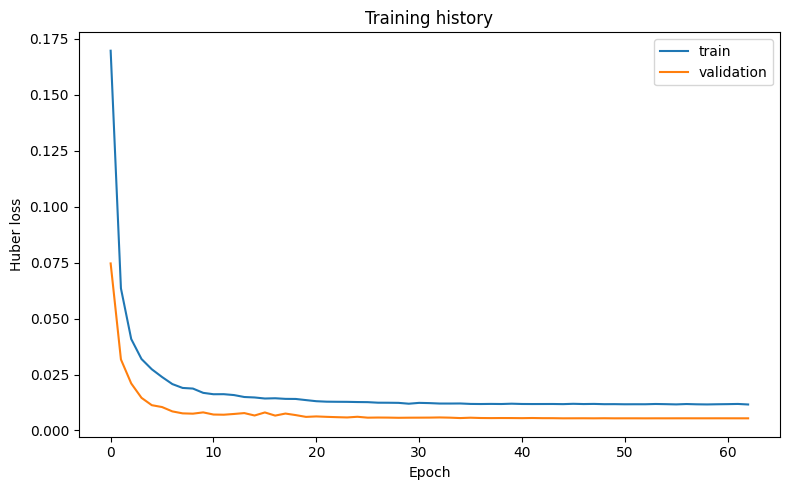

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Huber loss")
plt.title("Training history")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Predict, inverse-transform, and enforce physical limits


In [10]:
predicted_scaled = model.predict(X_test, verbose=0).reshape(-1, 1)
predicted = target_scaler.inverse_transform(predicted_scaled).ravel()
actual = load_data.iloc[test_positions][TARGET_COLUMN].to_numpy(dtype=float)

predicted = np.maximum(predicted, 0.0)
upper_bound = load_data.iloc[test_positions]["wind_installed"].to_numpy(dtype=float) * 1.05
predicted = np.minimum(predicted, upper_bound)

predictions = pd.DataFrame({
    TIME_COLUMN: test_times,
    "actual": actual,
    "predict": predicted,
})
predictions["error"] = predictions["predict"] - predictions["actual"]
predictions["absolute_error"] = predictions["error"].abs()
predictions.head()


,time,actual,predict,error,absolute_error
0,2024-10-20 05:00:00,19432.666161,19299.806641,-132.859520,132.859520
1,2024-10-20 06:00:00,19320.141465,19136.507812,-183.633652,183.633652
2,2024-10-20 07:00:00,19050.406146,19098.332031,47.925885,47.925885
3,2024-10-20 08:00:00,18882.110128,18775.955078,-106.155050,106.155050
4,2024-10-20 09:00:00,18096.568201,18624.662109,528.093908,528.093908


## 9. Consistent, zero-safe metrics


In [11]:
metrics = regression_metrics(
    predictions["actual"],
    predictions["predict"],
    mape_min_actual=50.0,
)
pd.Series(metrics)


sample_count             1754.000000
mean_error_mw              49.637040
mae_mw                    537.859804
rmse_mw                   741.147773
mse_mw2                549300.021224
nmse                        0.011067
r2                          0.988933
smape_percent               5.955171
masked_mape_percent         6.286052
mape_min_actual_mw         50.000000
mape_sample_count        1754.000000
dtype: float64

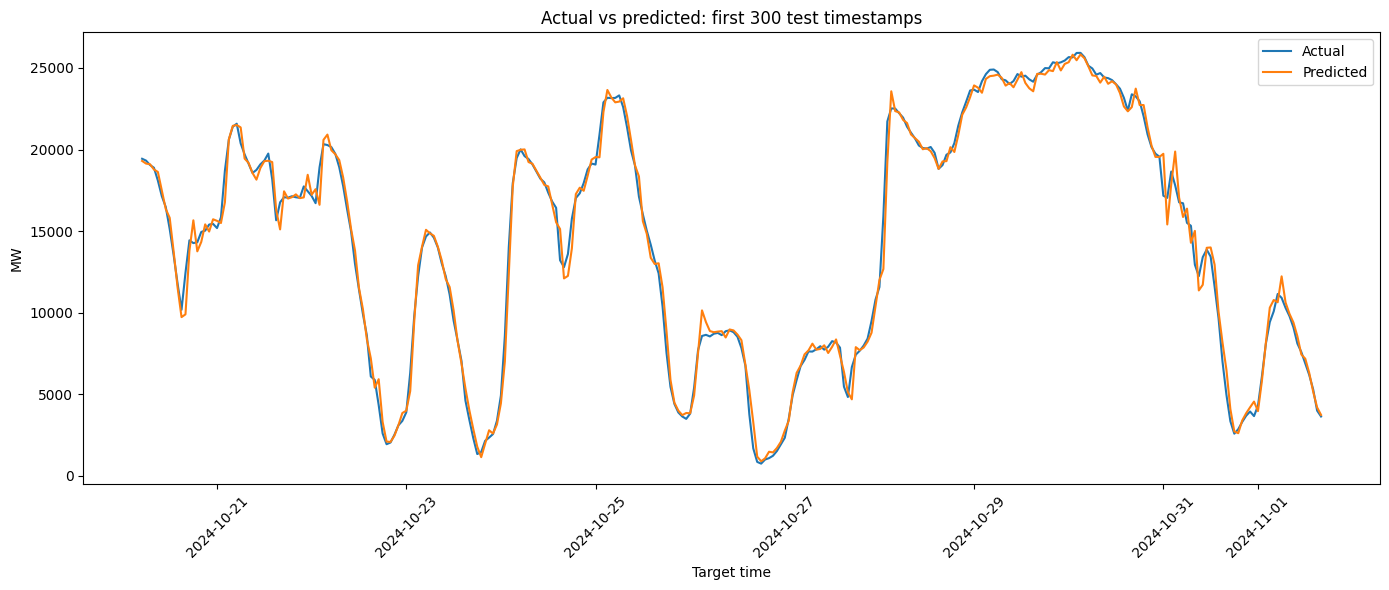

In [12]:
view = predictions.iloc[:min(300, len(predictions))]
plt.figure(figsize=(14, 6))
plt.plot(view[TIME_COLUMN], view["actual"], label="Actual")
plt.plot(view[TIME_COLUMN], view["predict"], label="Predicted")
plt.xlabel("Target time")
plt.ylabel("MW")
plt.title("Actual vs predicted: first 300 test timestamps")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


## 10. Save unique model, preprocessing, predictions, and history


In [ ]:
model_path = OUTPUT_DIR / f"{ARTIFACT_NAME}.keras"
model.save(model_path)
joblib.dump(
    {
        "feature_transformer": feature_transformer,
        "target_scaler": target_scaler,
        "target_column": TARGET_COLUMN,
        "history_hours": HISTORY_HOURS,
        "validation_start": validation_start,
        "test_start": test_start,
    },
    OUTPUT_DIR / f"{ARTIFACT_NAME}_preprocessing.joblib",
)
pd.DataFrame(history.history).to_csv(
    OUTPUT_DIR / f"{ARTIFACT_NAME}_training_history.csv", index=False
)
predictions.to_csv(OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.csv", index=False)
predictions.to_excel(OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.xlsx", index=False)
pd.Series(metrics).to_json(OUTPUT_DIR / f"{ARTIFACT_NAME}_metrics.json", indent=2)
print("Saved model:", model_path)
print("Saved predictions:", OUTPUT_DIR / f"{ARTIFACT_NAME}_predictions.xlsx")
